In [31]:
import numpy as np
import matplotlib.pyplot as plt

# FUNÇÕES IMPLEMENTADAS PARA CÁLCULO DA DFT, IDFT E CONVOLUÇÃO CIRCULAR

def W_kn_N (k,n,N):
    return np.exp(-2j * np.pi * k * n / N)

def DFT(x_n_teste, N):

    # Zero-padding do sinal x(n) para ter N amostras:
    x_n = np.pad(x_n_teste, (0, N - len(x_n_teste)), 'constant')

    # Definição da matriz W_n
    W_n = np.zeros((N,N), dtype=complex)

    for k in range (0, N, 1):
        for n in range (0, N, 1):
            W_n[k][n] = W_kn_N(k,n,N)

    # Cálculo da DFT
    X_k = np.zeros(N, dtype=complex)
    for k in range(N):
        X_k[k] = np.sum(W_n[k] * x_n )

    return X_k

def FFT (x_n):

    X = np.array(x_n, dtype=complex)
    N = len(X)

    # Validação: N deve ser potência de 2
    if (N <= 0) or (N & (N - 1) != 0):
        raise ValueError("O tamanho do sinal N precisa ser uma potência de 2.")

    num_estagios = int(np.log2(N))

    for estagio in range(num_estagios):

        N_atual = N // (2 ** estagio)
        N_2 = N_atual // 2

        for inicio in range(0, N, N_atual):
            for k in range(N_2):
                W_nN = W_kn_N(1, k, N_atual)

                idx1 = inicio + k
                idx2 = inicio + k + N_2

                u = X[idx1]
                v = X[idx2]

                X[idx1] = u + v
                X[idx2] = (u - v) * W_nN

    X_k = np.zeros(N, dtype=complex)
    for k in range(N):
        idx_invertido = int(f"{k:0{num_estagios}b}"[::-1], 2)
        X_k[idx_invertido] = X[k]

    return X_k

N      | DFT Manual (s)  | FFT Manual (s)  | FFT NumPy (s)  
------------------------------------------------------------
16     | 0.000920        | 0.000183        | 0.000084       
32     | 0.001885        | 0.000289        | 0.000072       
64     | 0.008827        | 0.000841        | 0.000090       
128    | 0.035317        | 0.001831        | 0.000107       
256    | 0.238790        | 0.003758        | 0.000127       
512    | 0.462621        | 0.005193        | 0.000098       
1024   | 1.679195        | 0.010326        | 0.000093       
2048   | 5.962398        | 0.065083        | 0.000136       
4096   | 23.847942       | 0.055325        | 0.000232       
8192   | 93.962294       | 0.121891        | 0.000249       
16384  | 385.709484      | 0.267625        | 0.000526       


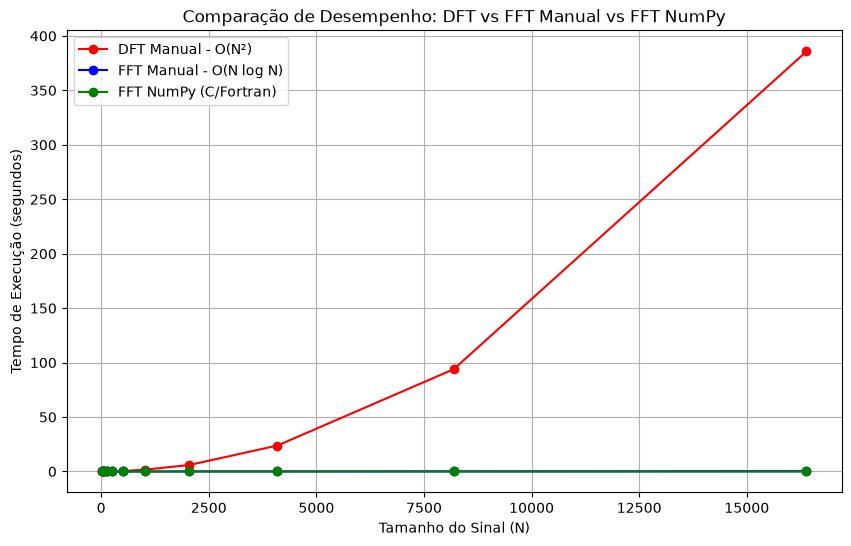

In [ ]:
import time

def comparar_tempos():
    # Tamanhos N para o teste
    tamanhos_N = [16, 32, 64, 128, 256, 512, 1024, 2048, 4096, 8192, 16384]

    tempos_dft = []
    tempos_fft = []
    tempos_numpy = []

    print(
        f"{'N':<6} | {'DFT Manual (s)':<15} | {'FFT Manual (s)':<15} | {'FFT NumPy (s)':<15}"
    )
    print("-" * 60)

    for N in tamanhos_N:
        x = np.random.rand(N) + 1j * np.random.rand(N)

        # 1. Medição da DFT Manual (x, N)
        inicio_dft = time.perf_counter()
        _ = DFT(x, N)
        fim_dft = time.perf_counter()
        tempo_dft = fim_dft - inicio_dft
        tempos_dft.append(tempo_dft)

        # 2. Medição da FFT Manual (x)
        inicio_fft = time.perf_counter()
        _ = FFT(x)
        fim_fft = time.perf_counter()
        tempo_fft = fim_fft - inicio_fft
        tempos_fft.append(tempo_fft)

        # 3. Medição da FFT do NumPy (np.fft.fft)
        inicio_numpy = time.perf_counter()
        _ = np.fft.fft(x)
        fim_numpy = time.perf_counter()
        tempo_numpy = fim_numpy - inicio_numpy
        tempos_numpy.append(tempo_numpy)

        print(
            f"{N:<6} | {tempo_dft:<15.6f} | {tempo_fft:<15.6f} | {tempo_numpy:<15.6f}"
        )

    # --- Plotagem do Gráfico ---
    plt.figure(figsize=(10, 6))

    plt.plot(tamanhos_N, tempos_dft, "o-r", label="DFT Manual - O(N²)")
    plt.plot(tamanhos_N, tempos_fft, "o-b", label="FFT Manual - O(N log N)")
    plt.plot(tamanhos_N, tempos_numpy, "o-g", label="FFT NumPy (C/Fortran)")

    plt.xlabel("Tamanho do Sinal (N)")
    plt.ylabel("Tempo de Execução (segundos)")
    plt.title("Comparação de Desempenho: DFT vs FFT Manual vs FFT NumPy")
    plt.legend()
    plt.grid(True)

    # Dica: Descomente a linha abaixo caso a curva do NumPy fique colada no zero
    # plt.yscale('log')

    plt.show()

comparar_tempos()